# Training utilities: Gender CNN với ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard (PyTorch)

Bản PyTorch của `Yêu cầu/examples/4. Training Utilities/2_Human_Gender_CNN.ipynb`. Dữ liệu và mô hình giống hệt `2. CNN + MLP/2_Human_Gender_CNN`; khác ở mục (3):

- ModelCheckpoint: lưu mô hình mỗi khi `val_loss` tốt hơn.
- EarlyStopping: dừng khi `val_loss` không giảm 5 epoch liền.
- ReduceLROnPlateau: nhân lr với 0.1 khi `val_loss` đứng yên 5 epoch (lr không nhỏ hơn 1e-4).
- TensorBoard: ghi loss/accuracy theo epoch.
- Adam lr **1e-3** (bản thư mục 2 dùng 1e-4), số epoch đặt rất lớn để EarlyStopping quyết định lúc dừng.

| | Keras gốc (Keras 2.0.9, GTX 1080) | PyTorch |
|---|---|---|
| Số tham số | 4.063.570 | kiểm bằng `assert` ở mục (2) |
| Dừng ở epoch | 32 (tốt nhất epoch 27) | xem mục (3) |
| Test accuracy (checkpoint tốt nhất) | 0.8773 | xem mục (4) |
| Test loss | 0.3237 | xem mục (4) |

Mốc so sánh: đoán toàn "male" đã được 0.7885 (dữ liệu lệch lớp, xem notebook thư mục 2).

# Import libraries

Keras gốc:
```python
import keras
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam

# Training utilities
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard
```
Bản PyTorch: `ModelCheckpoint`, `EarlyStopping`, `TensorBoard`, `reduce_lr_on_plateau` viết trong `pytorch/common.py` (PyTorch không có sẵn callback; `ReduceLROnPlateau` có sẵn trong `torch.optim.lr_scheduler`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import torch.nn.functional as F
from collections import OrderedDict
import matplotlib.pyplot as plt

# True: chỉ chạy thử (ít dữ liệu, vài epoch) để kiểm code trên CPU; bản nộp phải là False (chạy GPU)
CHAY_THU = False

set_seed(0)
device = get_device()

torch 2.11.0+cu130 | thiết bị: cuda (Tesla T4)


In [2]:
num_classes = 2   # male vs. female
TEN = "tu_2_Human_Gender_CNN"   # tiền tố tu_ để không trùng bản thư mục 2

# (1) Data

Giống `2. CNN + MLP/2_Human_Gender_CNN`: đọc 4 file `.npy` trong `data/gender/`, `np.rot90(k=3)`, **không chia 255**, `(N, 64, 64, 1)` → `(N, 1, 64, 64)`, nhãn one-hot → chỉ số lớp. Dữ liệu xếp male trước, female sau; `shuffle=True` xáo lại mỗi epoch.

In [3]:
def doc_gender(ten_x, ten_y, n=None):
    x = np.load(DATA_DIR / "gender" / ten_x, mmap_mode="r")
    y = np.load(DATA_DIR / "gender" / ten_y)
    if n is not None:                            # chạy thử: lấy rải đều cả file vì dữ liệu xếp male trước, female sau
        buoc = len(y) // n
        x, y = x[::buoc][:n], y[::buoc][:n]
    x = np.rot90(x, k=3, axes=(1, 2))           # như gốc
    return to_nchw(x), onehot_to_index(y)      # (N, 1, 64, 64) float32 0–255, nhãn 0/1

n = 1000 if CHAY_THU else None
x_train, y_train = doc_gender('64_64_11938_4098_train_x_onehot.npy', '64_64_11938_4098_train_y_onehot.npy', n)
x_test, y_test = doc_gender('64_64_5968_4098_val_x_onehot.npy', '64_64_5968_4098_val_y_onehot.npy', n)
print(tuple(x_train.shape), tuple(x_test.shape))

(11938, 1, 64, 64) (5968, 1, 64, 64)


# (2) Declare model

Giống hệt `2. CNN + MLP/2_Human_Gender_CNN` (5 khối conv 16×2, 32×3, 64×3, 128×3, 256×3, mỗi khối MaxPool + Dropout 0.2 → FC 1024 → FC 1024 → FC 2).

In [4]:
def khoi_conv(stt, c_in, c_out, so_conv):
    """Một khối: so_conv × [Conv 3×3 same + ReLU] → MaxPool 2×2 → Dropout 0.2, tên lớp như Keras."""
    lop = []
    for k in range(1, so_conv + 1):
        lop += [(f"conv{stt}_{k}", nn.Conv2d(c_in if k == 1 else c_out, c_out, 3, padding=1)),
                (f"relu{stt}_{k}", nn.ReLU())]
    lop += [(f"pool{stt}", nn.MaxPool2d(2)), (f"conv_dropout{stt}", nn.Dropout(0.2))]
    return nn.Sequential(OrderedDict(lop))


class GenderCNN(nn.Module):
    """Tên gốc 'mnist_mlp' (gốc giữ tên của bài MLP)."""

    def __init__(self, num_classes=2):
        super().__init__()
        self.block1 = khoi_conv(1, 1, 16, 2)      # (N, 16, 32, 32)
        self.block2 = khoi_conv(2, 16, 32, 3)     # (N, 32, 16, 16)
        self.block3 = khoi_conv(3, 32, 64, 3)     # (N, 64, 8, 8)
        self.block4 = khoi_conv(4, 64, 128, 3)    # (N, 128, 4, 4)
        self.block5 = khoi_conv(5, 128, 256, 3)   # (N, 256, 2, 2)
        self.flatten = nn.Flatten()               # (N, 1024)
        self.fc1 = nn.Linear(256 * 2 * 2, 1024)
        self.fc_dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(1024, 1024)
        self.fc_dropout2 = nn.Dropout(0.2)
        self.fc3_10ways_softmax = nn.Linear(1024, num_classes)   # trả logits

    def forward(self, x):                         # x: (N, 1, 64, 64), giá trị 0–255
        x = self.block5(self.block4(self.block3(self.block2(self.block1(x)))))
        x = self.flatten(x)
        x = self.fc_dropout1(F.relu(self.fc1(x)))
        x = self.fc_dropout2(F.relu(self.fc2(x)))
        return self.fc3_10ways_softmax(x)


model = init_keras_like(GenderCNN(num_classes)).to(device)
summary(model, input_size=(1, 1, 64, 64), depth=2)
n_params = count_params(model)
print("Số tham số PyTorch:", n_params)
assert n_params == 4_063_570

Số tham số PyTorch: 4063570


# (3) Train defined model

Keras gốc:
```python
loss = 'categorical_crossentropy'
lr = 0.001
model.compile(loss=loss, optimizer=Adam(lr=lr), metrics=['accuracy'])
batch_size = 128
epochs = 100000 # Since we are going to use EarlyStopping, the number of epochs should be as large as possible!

check_pointer = ModelCheckpoint(monitor='val_loss', save_best_only=True,
                                filepath='{epoch:06d}-{loss:.4f}-{acc:.4f}-{val_loss:.4f}-{val_acc:.4f}.hdf5')
early_stopping_after_epochs = 5
early_stopping = EarlyStopping(monitor='val_loss', patience=early_stopping_after_epochs)
reduce_lr_after_epochs = 5
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=reduce_lr_after_epochs, min_lr=0.0001)
tf_board = TensorBoard(log_dir='./logs')

model.fit(x_train, y_train, validation_data=(x_test, y_test), batch_size=batch_size, epochs=epochs,
          callbacks=[check_pointer, early_stopping, reduce_lr, tf_board])
```

Khác Keras:
- `ModelCheckpoint` lưu `state_dict` vào `results/tu_2_Human_Gender_CNN/checkpoints/` (đuôi `.pt`, git bỏ qua), tên file theo đúng mẫu của gốc. Epoch đếm từ 1 như log gốc.
- `EarlyStopping` đếm như Keras: dừng sau 5 epoch liền không giảm `val_loss` (log gốc: tốt nhất 27, dừng 32) và **không** tự khôi phục trọng số tốt nhất; phải nạp checkpoint như ô (3.1).
- `ReduceLROnPlateau` là scheduler của PyTorch, truyền qua `scheduler=`; `fit` gọi `scheduler.step(val_loss)` sau mỗi epoch. PyTorch giảm lr ở epoch xấu thứ 6 (patience + 1); trong log gốc lr chưa lần nào bị giảm vì EarlyStopping dừng trước.
- `TensorBoard` ghi vào `runs/tu_2_Human_Gender_CNN` (git bỏ qua).

In [5]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

batch_size = 128
epochs = 3 if CHAY_THU else 100000   # EarlyStopping quyết định lúc dừng

train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

# ===============================
#      Training utilities
# ===============================
ckpt_dir = RESULTS_DIR / TEN / "checkpoints"
import shutil   # xóa checkpoint và log của lần chạy trước để chỉ còn file của lần này
shutil.rmtree(ckpt_dir, ignore_errors=True)
shutil.rmtree(RUNS_DIR / TEN, ignore_errors=True)
check_pointer = ModelCheckpoint(
    str(ckpt_dir / "{epoch:06d}-{loss:.4f}-{acc:.4f}-{val_loss:.4f}-{val_acc:.4f}.pt"),
    monitor='val_loss', save_best_only=True)

early_stopping_after_epochs = 1 if CHAY_THU else 5
early_stopping = EarlyStopping(monitor='val_loss', patience=early_stopping_after_epochs)

reduce_lr_after_epochs = 5
reduce_lr = reduce_lr_on_plateau(optimizer, factor=0.1, patience=reduce_lr_after_epochs, min_lr=0.0001)

tf_board = TensorBoard(log_dir=RUNS_DIR / TEN)
# Xem: mở Anaconda Prompt tại thư mục BTL03, chạy  tensorboard --logdir runs

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs, metric=accuracy,
              callbacks=[check_pointer, early_stopping, tf_board], scheduler=reduce_lr)
train_time = time.time() - starting_time
print('> training time is %.4f minutes' % (train_time / 60))
print('> dừng sau epoch %d, tốt nhất epoch %d (val_loss %.4f)'
      % (len(history["loss"]), check_pointer.best_epoch, check_pointer.best))

I0000 00:00:1795755277.724068     361 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


fit: train trên cuda (Tesla T4)
Epoch 1/100000 - 6.3s - loss: 0.5431 - acc: 0.7804 - val_loss: 0.5132 - val_acc: 0.7885 - lr: 1.0e-03
Epoch 00001: val_loss inf → 0.51322, lưu 000001-0.5431-0.7804-0.5132-0.7885.pt
Epoch 2/100000 - 6.0s - loss: 0.5138 - acc: 0.7885 - val_loss: 0.5146 - val_acc: 0.7885 - lr: 1.0e-03
Epoch 00002: val_loss không cải thiện so với 0.51322
Epoch 3/100000 - 6.1s - loss: 0.5128 - acc: 0.7885 - val_loss: 0.5120 - val_acc: 0.7885 - lr: 1.0e-03
Epoch 00003: val_loss 0.51322 → 0.51195, lưu 000003-0.5128-0.7885-0.5120-0.7885.pt
Epoch 4/100000 - 6.2s - loss: 0.5119 - acc: 0.7885 - val_loss: 0.5077 - val_acc: 0.7885 - lr: 1.0e-03
Epoch 00004: val_loss 0.51195 → 0.50770, lưu 000004-0.5119-0.7885-0.5077-0.7885.pt
Epoch 5/100000 - 6.3s - loss: 0.5123 - acc: 0.7885 - val_loss: 0.5080 - val_acc: 0.7885 - lr: 1.0e-03
Epoch 00005: val_loss không cải thiện so với 0.50770
Epoch 6/100000 - 6.3s - loss: 0.5114 - acc: 0.7885 - val_loss: 0.5111 - val_acc: 0.7885 - lr: 1.0e-03
Epoch

### Training time
- Gốc: GTX 1080 khoảng 3,19 phút cho 32 epoch. Validation accuracy ~87,7% ở epoch 27; không dùng training utilities (bản thư mục 2) chỉ ~82,6%.
- Bản PyTorch: xem hai dòng in ở trên.

### (3.1) Load trained model and evaluate it again with validation set

Keras gốc:
```python
model.load_weights('000027-0.2789-0.8976-0.3237-0.8773.hdf5')
model.evaluate(x_test, y_test)
```
Gốc gõ tay tên file tốt nhất; ở đây lấy từ `check_pointer.best_path`.

In [6]:
print("Nạp:", Path(check_pointer.best_path).name)
model.load_state_dict(torch.load(check_pointer.best_path, map_location=device))
evaluate(model, test_loader, loss_fn, accuracy)

Nạp: 000042-0.2672-0.9014-0.3299-0.8809.pt


(0.3298518189476259, 0.8808646111002556)

### Checkpoint files

Gốc hiển thị ảnh chụp thư mục (`checkpoints.PNG`); ở đây liệt kê file thật. Chỉ còn các file của những epoch `val_loss` giảm, vì `save_best_only=True`.

In [7]:
for p in sorted(ckpt_dir.glob("*.pt")):
    print(p.name)

000001-0.5431-0.7804-0.5132-0.7885.pt
000003-0.5128-0.7885-0.5120-0.7885.pt
000004-0.5119-0.7885-0.5077-0.7885.pt
000007-0.5098-0.7883-0.5058-0.7885.pt
000008-0.5002-0.7893-0.4907-0.7912.pt
000010-0.4837-0.7915-0.4735-0.8081.pt
000012-0.4712-0.8006-0.4591-0.8140.pt
000013-0.4570-0.8060-0.4547-0.8145.pt
000014-0.4477-0.8144-0.4370-0.8185.pt
000016-0.4241-0.8303-0.4147-0.8279.pt
000018-0.4054-0.8398-0.4074-0.8355.pt
000019-0.3920-0.8459-0.4037-0.8391.pt
000020-0.3942-0.8431-0.3948-0.8422.pt
000022-0.3696-0.8566-0.3821-0.8492.pt
000024-0.3608-0.8602-0.3723-0.8554.pt
000025-0.3467-0.8682-0.3698-0.8566.pt
000026-0.3393-0.8681-0.3616-0.8633.pt
000028-0.3291-0.8745-0.3533-0.8670.pt
000031-0.3163-0.8804-0.3398-0.8758.pt
000032-0.3015-0.8865-0.3385-0.8758.pt
000033-0.2991-0.8891-0.3372-0.8747.pt
000034-0.2958-0.8881-0.3344-0.8705.pt
000038-0.2786-0.8935-0.3324-0.8802.pt
000041-0.2669-0.9004-0.3321-0.8789.pt
000042-0.2672-0.9014-0.3299-0.8809.pt


### TensorBoard

Gốc hiển thị ảnh chụp TensorBoard (`tfboard.PNG`). Log của bản PyTorch nằm ở `runs/tu_2_Human_Gender_CNN`; xem bằng lệnh `tensorboard --logdir runs`. Hình dưới vẽ cùng các đại lượng (loss, accuracy, lr theo epoch) từ `history`.

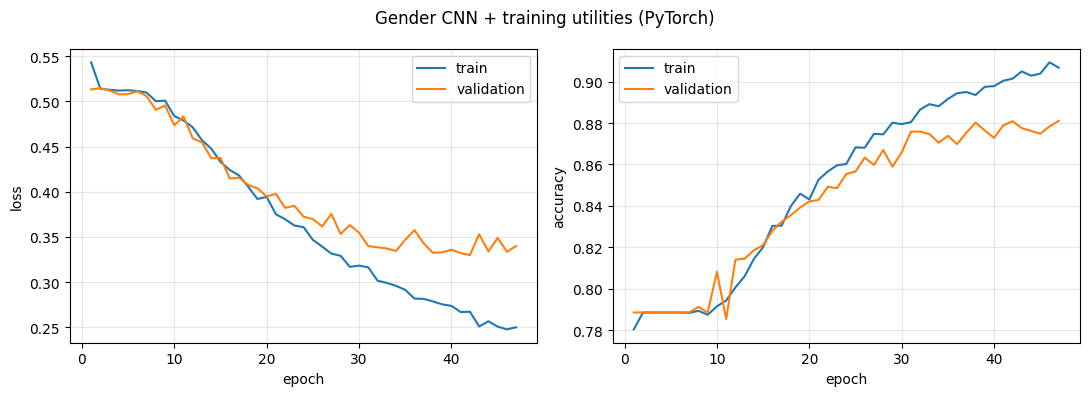

lr theo epoch: [0.001]


In [8]:
fig = plot_history(history, None if CHAY_THU else TEN, metric_label="accuracy",
                   title="Gender CNN + training utilities (PyTorch)")
plt.show()
print("lr theo epoch:", sorted(set(history["lr"]), reverse=True))

# (4) Evaluate trained model

Kết quả gốc (sau khi nạp checkpoint epoch 27): `Test loss: 0.3237`, `Test accuracy: 0.8773`.

In [9]:
score = evaluate(model, test_loader, loss_fn, accuracy)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.3298518189476259
Test accuracy: 0.8808646111002556


In [10]:
if not CHAY_THU:
    save_history(history, TEN)
    save_metrics(TEN, test_loss=score[0], test_metric=score[1], n_params=n_params,
                 epochs_ran=len(history["loss"]), best_epoch=check_pointer.best_epoch,
                 train_time_s=train_time, device=device_name(device), seed=0,
                 lr_cuoi=history["lr"][-1])
    ghi_so_sanh(TEN, "4. Training Utilities", "test_acc", keras=0.8773, pytorch=score[1],
                keras_params=4063570, pytorch_params=n_params, epochs_keras=32,
                epochs_pytorch=len(history["loss"]), optimizer="Adam", lr=lr, batch=batch_size,
                device=device_name(device), train_time_s=train_time, seed=0,
                ghi_chu="4 callback; Keras dừng epoch 32 (tốt nhất 27); PyTorch tốt nhất epoch %d; "
                        "accuracy của checkpoint tốt nhất" % check_pointer.best_epoch)

so_sanh.csv: tu_2_Human_Gender_CNN | test_acc Keras 0.8773 | PyTorch 0.8809 | chênh 0.0036


In [11]:
def int2gender(num):
    if num == 0:
        return 'female'
    else:
        return 'male'

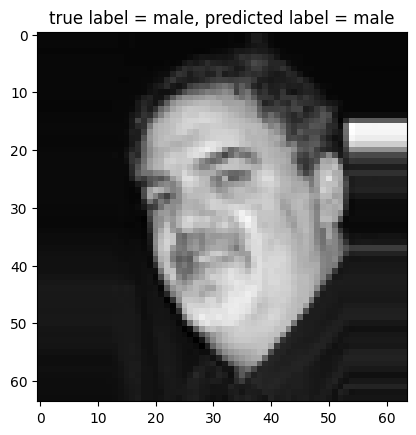

In [12]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = int(y_test[random_test_index])

pred_label = predict(model, test_img.unsqueeze(0))
pred_label = int(pred_label.argmax(dim=1))

plt.imshow(test_img[0], cmap='gray')
plt.title('true label = %s, predicted label = %s' % (int2gender(test_label), int2gender(pred_label)))
plt.show()